##Not Defteri Amacı ve Kapsamı

####Bu Jupyter defteri; geliştirilen makine öğrenmesi modelinin mimari ve veri tabanlı sınırlılıklarını teorik ve pratik düzeyde ele almaktadır. Çalışma, bu sınırlılıkların modelin genelleştirme yeteneği üzerindeki olumsuz etkilerini bertaraf etmek amacıyla uygulanan sistematik öznitelik mühendisliği (feature engineering) ve veri ön işleme adımlarını kapsamaktadır.

####Bu Defterin Konumu: Araştırma Sorusu, Hipotezler ve Akış

**Araştırma sorusu.** ChestMNIST üzerinde pnömoni tespiti yapılırken akciğer dışındaki bağlam bilgisi (cihaz/kablo/yazı/çekim koşulu izleri) bastırılırsa, model karar mekanizmasını daha çok akciğer dokusuna dayandırır mı ve bunun genel tahmin performansına bedeli nedir?

**Hipotezler** (işlemsel kabul ölçütleri `step_03` defterinde, sonuçlar görülmeden önce tanımlanmıştır):

| Kod | Hipotez |
|---|---|
| H1 | Akciğer dışı bölgede, pnömoni etiketiyle ilişkili öğrenilebilir bir sinyal vardır (kısayol potansiyeli). |
| H2 | Soft mask ile eğitilen model, ham veriyle eğitilene göre akciğer dışı bilgiye daha az bağımlıdır. |
| H3 | Soft mask modelinin Grad-CAM dikkati akciğer içinde daha yoğundur. |
| H4 | Soft mask, genel test performansını anlamlı biçimde düşürmez (eşdeğerlik/aşağı olmama). |

**Akış.** Veri yükle → kopya oluştur → akciğer segmentasyonu → soft mask → maske kalite kontrolü (eşik + fallback) → maskeleri ve bayrakları kaydet → *(step_03)* karşılaştırmalı eğitim, kısayol testleri, Grad-CAM.

In [ ]:
# [Ek] Google Drive'ı bağla
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Colab dışında çalışılıyor; dosya yollarını kontrol edin.")

Mounted at /content/drive


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_dir = '/content/drive/MyDrive/Machine Learning/Datasets/MedMNIST/'
file_path = os.path.join(target_dir, "chestmnist_128.npz")
with np.load(file_path) as npz:
    data = {anahtar: npz[anahtar] for anahtar in npz.files}  # tek seferde belleğe al

####Veri Seti Hakkında Teknik Notlar ve Sınırlılıklar

**Kaynak.** ChestMNIST, NIH **ChestX-ray14** veri setinin (~112 bin ön yüzlü göğüs röntgeni, 14 hastalık etiketi; Wang ve ark., CVPR 2017 makalesi 8 etiketli ChestX-ray8'i tanıtır, yayımlanan veri sürümü 14 etiketlidir) MedMNIST v2 koleksiyonundaki (Yang ve ark., *Scientific Data*, 2023) küçültülmüş ve standartlaştırılmış sürümüdür. Elimizdeki dosya **128×128** gri tonlamalı sürümdür.

**Etiketler.** Etiketler radyologlar tarafından görüntü üzerinden değil, **radyoloji raporlarından NLP ile otomatik çıkarılmıştır** (zayıf/programatik etiketleme). Bu nedenle etiketler "altın standart" değil, gürültü içeren vekil etiketlerdir.

**Sınırlılıklar (bu veri sürümüne özgü):**
- **Üst-veri (metadata) yok.** MedMNIST dosyasında hasta kimliği, çekim pozisyonu (PA/AP), yaş, cinsiyet bulunmaz. Dolayısıyla (i) PA/AP kısayolunu doğrudan ölçemeyiz, (ii) hasta düzeyinde sızıntıyı kendimiz doğrulayamayız; resmî bölünmenin hasta bazlı olduğuna güveniyoruz.
- **Çözünürlük kaybı.** 1024×1024 → 128×128 küçültme, ince doku değişikliklerini (pnömoninin erken/hafif formları) ve küçük cihaz/yazı izlerini zayıflatır. Bu hem hastalık sinyalini hem de kısayol sinyalini etkiler.
- **Çok etiketli yapı.** Bu çalışma 14 etiketin yalnızca biriyle (pnömoni, indeks 6) ilgilenir; diğer bulguların (efüzyon, konsolidasyon vb.) pnömoniyle birlikte bulunması model davranışını etkileyebilir.

####Veri seti hikayesini incelediğimizde önceden aynı verilerle eğitilmiş modellerin röntgen açısını görerek Ayakta (PA) ve yatışı olan/ağır hastalar (AP) tespitinden veya pnömoni ve diğer hastalıkların tedavisi için kullanılan akciğer tüpleri'nden modellerin shortcut learning yaptığı tespit edilmiştir. Bu kısmı daha iyi anlamlandırmanız için verileri görselleştirelim. (Bkz. Görsel 6 ve Görsel 7)

#### Kısayol Öğrenme (Shortcut Learning): Kavram ve Literatür Nüansı

**Kavram.** Kısayol öğrenme, modelin hedef kavram yerine veri toplama sürecinden gelen ilişkili ama nedensel olmayan ipuçlarını öğrenmesidir (Geirhos ve ark., *Nature Machine Intelligence*, 2020).

**Tıbbi görüntülemedeki örnekler.**
- Zech ve ark. (*PLOS Medicine*, 2018): pnömoni modelleri hastane sistemine özgü görüntü özelliklerini öğrenebilmekte; dış hastanede performans düşmektedir.
- DeGrave ve ark. (*Nature Machine Intelligence*, 2021): COVID-19 röntgen modellerinde kısayol kullanımı gösterilmiştir.
- Oakden-Rayner (*Academic Radiology*, 2020): ChestX-ray14 etiket gürültüsü ve gözlenen cihaz izleri (özellikle pnömotoraks–göğüs tüpü ilişkisi) tartışılmıştır.

**Nüans (dürüstlük notu).** Göğüs tüpü kısayolu literatürde en net biçimde **pnömotoraks** için gösterilmiştir. Pnömoni için daha çok **hastane/cihaz kaynağı** ve **hasta durumunu dolaylı gösteren çekim koşulu (PA/AP, taşınabilir cihaz)** tartışılır. Dolayısıyla bu çalışmada kısayolun varlığı **varsayım değil, test edilecek hipotezdir (H1)**; bu defterin amacı kısayolu *kanıtlamak* değil, *bastırma stratejisini* hazırlamak, kanıt/çürütme `step_03`'te aranacaktır.

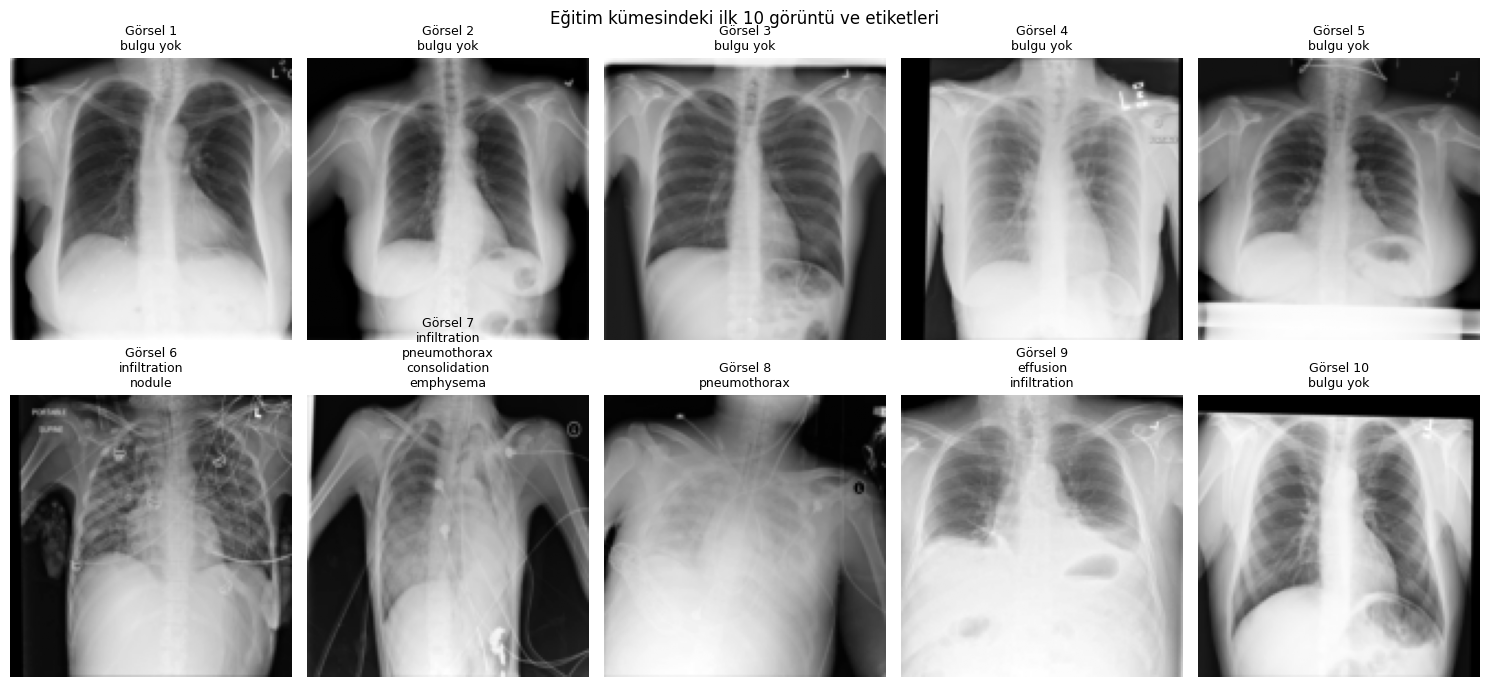

In [ ]:
!pip install -q medmnist==3.0.2
from medmnist import ChestMNIST, INFO

train_labels = data["train_labels"]
info = INFO["chestmnist"]
LABELS = [info["label"][str(i)] for i in range(len(info["label"]))]
def etiket_metni(etiket):
    adlar = [LABELS[i] for i in np.flatnonzero(etiket)]
    return "\n".join(adlar) if adlar else "bulgu yok"

train_images = data["train_images"]

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_images[i], cmap="gray")
    ax.set_title(f"Görsel {i + 1}\n{etiket_metni(train_labels[i])}", fontsize=9)
    ax.axis("off")
plt.suptitle("Eğitim kümesindeki ilk 10 görüntü ve etiketleri")
plt.tight_layout()
plt.show()

#### Görsellerden Çıkarımlar ve Dikkat Edilecekler

Yukarıdaki ilk 10 görüntü **rastgele seçilmemiş**, veri sırasındaki ilk örneklerdir; yalnızca sezgi kazandırmak içindir, kanıt değildir. Bu çözünürlükte tüp, kablo ve kenar yazıları genellikle seçilemeyecek kadar küçülür; bu da soft mask'ın etkisini **128 pikselde sınırlı** kılabilir (bkz. Sınırlılıklar). Metindeki "bkz. Görsel 6 ve Görsel 7" atıfları, sunumdaki şekil numaralarıdır.

####Şimdi görmüş olduğumuz röntgen görsellerinden de yola çıkacağımız üzere yukarda bahsedilen (bkz. Görsel 6 ve Görsel 7) bariz bir şekilde tedavi yönteminden kaynaklı shortcut learning ihtimali olası. Bu durumun önüne geçmek için bu notebook'da Soft Mask kullanacağız. Bu adımlara başlamadan önce indirdiğimiz orijinal verimizi koruyarak kopya üstünden çalışalım. Olası bir değişiklik/yeni yöntem kullanımı durumunda orijinal veriyi tekrardan indirmek durumunda kalmayız.

####Bellek ve Tekrarlanabilirlik Notu

128×128 uint8 görüntüler: train ≈ 1,29 GB, val ≈ 0,18 GB, test ≈ 0,37 GB; toplam **≈ 1,8 GB**. `deepcopy` ile orijinal + kopya ≈ 3,7 GB, akciğer maskeleri (aşağıda) ≈ 1,8 GB daha ekler. Ücretsiz Colab RAM'i (~12 GB) için yeterlidir ancak **model eğitimini bu defterle aynı oturumda yapmayın**.

In [ ]:
!pip install -q torchxrayvision opencv-python-headless

In [ ]:
import copy
import torch, cv2
import torchxrayvision as xrv

data_copy = copy.deepcopy(data)                               # tüm işlemler bunun üstünde

PNEUMONIA_IDX = 6                                             # etiket sırası: 6 = pneumonia

print(list(data_copy.keys()))
for k, v in data_copy.items():
    print(k, v.shape, v.dtype)
for s in ["train", "val", "test"]:
    print(s, "pnömoni oranı:", data_copy[f"{s}_labels"][:, PNEUMONIA_IDX].mean().round(4))

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
train_images (78468, 128, 128) uint8
train_labels (78468, 14) uint8
val_images (11219, 128, 128) uint8
val_labels (11219, 14) uint8
test_images (22433, 128, 128) uint8
test_labels (22433, 14) uint8
train pnömoni oranı: 0.0125
val pnömoni oranı: 0.0119
test pnömoni oranı: 0.0108


#### Sınıf Dengesizliğinin Sayısal Sonucu

Pnömoni oranları train/val/test için yaklaşık %1,25 / %1,19 / %1,08'dir. Bu, yaklaşık **981 / 134 / 242 pozitif örnek** demektir (oranlar × küme boyutu). Üç sonuç çıkar: (i) **doğruluk (accuracy) anlamsızdır**, hep "sağlıklı" diyen model ≈ %98,9 doğruluk alır; (ii) AUPRC'nin rastgele taban çizgisi sınıf oranıdır (≈ 0,011); (iii) test kümesinde yalnızca ~242 pozitif olduğu için metriklerin güven aralıkları geniştir, küçük farklar anlamlı sayılamaz.

####Yukarıdaki işlem sayesinde verilerimizi *data_copy* olarak kopyaladık. Şimdi ise röntgen görsellerimize Soft Mask işlemlerini uygulayacağız. Bunun için gereken parametreleri ve maskeleme fonksiyonlarını yazalım.

#### Soft Mask Yönteminin Ayrıntıları ve Olası Sorunlar

**Yöntem özeti.** (1) ChestX-Det üzerinde eğitilmiş hazır PSPNet (Zhao ve ark., CVPR 2017; `torchxrayvision` kütüphanesi, Cohen ve ark., 2022) sol ve sağ akciğer kanallarını tahmin eder; (2) iki kanalın pikselsel maksimumu alınır (birleşim); (3) 0,5'te eşiklenir; (4) 9 piksellik eliptik çekirdekle genişletilir; (5) Gauss bulanıklığıyla yumuşatılır; (6) çarpan haritası `w = ALPHA + (1-ALPHA)·maske` ile görüntü piksel piksel çarpılır. Akciğer içinde `w=1`, dışında `w=ALPHA=0,25`.

**Olası sorunlar ve sınırlılıklar.**
1. **Alan kayması (domain shift):** Segmentasyon modeli yüksek çözünürlüklü röntgenlerle eğitildi; biz 128×128 görüntüyü 512×512'ye *büyütüyoruz*. Büyütme bilgi eklemez, bulanık girdide maske kalitesi düşebilir.
2. **Referans maske yok:** Elimizde gerçek akciğer maskesi olmadığı için Dice/IoU **hesaplayamıyoruz**; maske kalitesini yalnızca vekil ölçütlerle (maske alanı dağılımı) ve görsel incelemeyle değerlendiriyoruz.
3. **Hastalığın maskeyi bozması:** Konsolidasyon (pnömoninin görüntüdeki karşılığı) akciğer dokusunu yoğunlaştırır; segmentasyon bu bölgeleri akciğer saymayabilir. Eğer öyleyse, **maske alanı en küçük çıkan görüntüler pnömoniyle zenginleşir** ve onları atmak seçilim yanlılığı yaratır (aşağıda test ediliyor).
4. **Soft mask kısayolu silmez, bastırır:** Dış bölgeyi 0,25 ile çarpmak *doğrusal bir ölçeklemedir*; bilgi yok olmaz, genliği azalır. Evrişimli ağ ve normalizasyon katmanları bu ölçeği kısmen telafi edebilir. Bu yüzden başarı varsayılmaz, `step_02`'te H2 ile ölçülür.
5. **Hiperparametreler ayarlanmadı:** `ALPHA`, `DILATE_PX`, `BLUR_PX` bir ablasyonla seçilmedi. `ALPHA ∈ {0; 0,25; 0,5}` karşılaştırması ileriki bir çalışma olarak bırakıldı.
6. **Çalışma zamanı:** Kayıtlı çalışma zamanı **TPU** olduğundan `device: cpu` çıktı. ~112 bin görüntü için 512×512 PSPNet çıkarımı CPU'da pratik değildir. **Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU** seçin.

In [ ]:
import cv2
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("UYARI: GPU yok. Tam veri için çıkarım çok yavaş olur; çalışma zamanını T4 GPU yapın.")  # DÜZELTME: uyarı eklendi

seg = xrv.baseline_models.chestx_det.PSPNet().to(device).eval()
LUNG_IDX = [seg.targets.index("Left Lung"), seg.targets.index("Right Lung")]

ALPHA = 0.25      # akciğer dışında kalacak parlaklık oranı (0 = tam silme)
DILATE_PX = 9     # maskeyi genişlet, kenarları kesme riskini azaltır
BLUR_PX = 15      # yumuşak geçiş (tek sayı olmalı)

@torch.no_grad()
def lung_masks(batch_u8):
    """batch_u8: (B,H,W) uint8 -> (B,H,W) float32 [0,1] akciğer olasılığı"""
    B, H, W = batch_u8.shape
    x = np.stack([cv2.resize(im, (512, 512)) for im in batch_u8]).astype(np.float32)
    x = (2 * (x / 255.0) - 1) * 1024                  # xrv normalizasyonu
    x = torch.from_numpy(x)[:, None].to(device)
    out = seg(x)
    if out.min() < 0 or out.max() > 1:                 # logit geldiyse sigmoid uygula
        out = torch.sigmoid(out)
    m = out[:, LUNG_IDX].max(dim=1).values.cpu().numpy()   # sol veya sağ akciğer
    return np.stack([cv2.resize(mm, (W, H)) for mm in m])

def soft_mask(img_u8, mask01):
    m = (mask01 > 0.5).astype(np.uint8)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (DILATE_PX, DILATE_PX))
    m = cv2.dilate(m, k).astype(np.float32)
    m = cv2.GaussianBlur(m, (BLUR_PX, BLUR_PX), 0)
    w = ALPHA + (1 - ALPHA) * m                          # içeride 1, dışarıda ALPHA
    return (img_u8.astype(np.float32) * w).clip(0, 255).astype(np.uint8)

device: cpu
UYARI: GPU yok. Tam veri için çıkarım çok yavaş olur; çalışma zamanını T4 GPU yapın.
If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/pspnet_chestxray_best_model_4.pth -O /root/.torchxrayvision/models_data/pspnet_chestxray_best_model_4.pth`
[██████████████████████████████████████████████████]


####Hazırladığımız bu maskeleme fonksiyonunu kopyaladığımız data üstüne uygulayalım.

In [ ]:
BATCH = 64
N_TEST = None   # None = tüm veri. Küçük bir değer yalnızca ilk N_TEST görüntüyü
                # maskeler, geri kalanı maskesiz kalır (kaydedilen dosya karışık olur). Hızlı deneme için kullanın.

from tqdm.auto import tqdm

def binary_lung(mask01):
    """soft_mask içinde kullanılan ikili + genişletilmiş maskenin aynısı (kayıt ve kısayol testleri için)."""
    m = (mask01 > 0.5).astype(np.uint8)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (DILATE_PX, DILATE_PX))
    return cv2.dilate(m, k)

areas = {}            # ham maske alanı oranı (>0.5 piksel oranı), işlenen görüntüler için
lung_masks_bin = {}   # step_2 için ikili akciğer maskeleri (işlenmeyenler 0 kalır)
for split in ["train", "val", "test"]:
    imgs_orig = data[f"{split}_images"]          # sadece okuma
    imgs_new  = data_copy[f"{split}_images"]     # yerinde değiştirilecek
    N, H, W = imgs_orig.shape
    n = N if N_TEST is None else min(N_TEST, N)
    area = np.zeros(n, dtype=np.float32)
    lung = np.zeros((N, H, W), dtype=np.uint8)

    for i in tqdm(range(0, n, BATCH), desc=split):
        j = min(i + BATCH, n)
        m = lung_masks(imgs_orig[i:j])           # maskeyi ORİJİNAL görüntüden üret
        for t in range(j - i):
            imgs_new[i + t] = soft_mask(imgs_orig[i + t], m[t])
            lung[i + t] = binary_lung(m[t])
            area[i + t] = (m[t] > 0.5).mean()

    areas[split] = area
    lung_masks_bin[split] = lung
    print(split, "işlenen:", n, "/", N, "| maske alanı ort/min/max:",
          area.mean().round(3), area.min().round(3), area.max().round(3))

train:   0%|          | 0/1227 [00:00<?, ?it/s]

####Çalıştırma Notları

- Tam veri için çalışma süresi GPU modeline göre değişir; tahmini birkaç on dakika ile bir saat arasındadır (bu defterde ölçülmedi, kendi ölçümünüzü not edin).
- Maske, **orijinal** görüntüden üretilir (maskeli görüntüden tekrar maske üretmek hata katlar).
- Kaydedilen `lung` maskeleri soft maskenin kullandığı **genişletilmiş ikili** maskedir; `step_03`'te "akciğer içi" / "akciğer dışı" tanımı bununla yapılır.

####Şimdi Soft Mask uyguladığımız görüntüler ve orijinal görüntüleri tutarlılık ve güncelleme görünümü olarak karşılaştırmak için görselleştirelim

In [ ]:
import matplotlib.pyplot as plt

def show_checks(split="train", k=6):
    area = areas[split]
    order = np.argsort(area)
    idx = list(order[:k//2]) + list(order[-k//2:])        # en küçük ve en büyük maske alanları
    fig, ax = plt.subplots(2, k, figsize=(2.2*k, 4.6))
    for c, i in enumerate(idx):
        ax[0, c].imshow(data[f"{split}_images"][i], cmap="gray")
        ax[0, c].set_title(f"alan={area[i]:.2f}", fontsize=8)
        ax[1, c].imshow(data_copy[f"{split}_images"][i], cmap="gray")
        ax[0, c].axis("off"); ax[1, c].axis("off")
    plt.show()

show_checks("train")

####Yukarıdaki karşılaştırma görsellerinde de görüldüğü üzere Soft Mask işlemi belirli alanlarda ciğer alanlarını tutturabilmişken parlaklığı yüksek olan ciğer röntgenlerinde tam alana hakim olamayarak küçük alanları ciğer bütünü olarak tanımlamıştır. İlerleyen süreçlerde verinin uygunluk durumuna göre belirli bir treshold belirleyerek kapsama alanının model eğitimine en uygun olacağı değer belirlenecek ve diğer veriler drop işlemine tabii tutulacaktır.

####Parlaklık–Maske Alanı İlişkisinin Nicel Doğrulaması

Yukarıdaki gözlem ("parlaklığı yüksek röntgenlerde maske küçük kalıyor") **görsel bir izlenimdir**. Aşağıdaki hücre bunu Spearman sıra korelasyonuyla nicel olarak sınar. Negatif ve anlamlı bir ilişki, segmentasyonun yoğunluğa duyarlı olduğunu ve eşik kararının yalnızca "bozuk maske" değil "parlak görüntü" ayrımı da yapabileceğini gösterir.

In [ ]:
# Ortalama parlaklık ile maske alanı arasındaki ilişki
from scipy.stats import spearmanr
n_tr = len(areas["train"])
mean_int = data["train_images"][:n_tr].reshape(n_tr, -1).mean(axis=1)
rho, p = spearmanr(mean_int, areas["train"])
print(f"Spearman rho = {rho:.3f}  (p = {p:.2g}, n = {n_tr})")
plt.figure(figsize=(5, 4))
plt.scatter(mean_int, areas["train"], s=3, alpha=0.3)
plt.xlabel("görüntü ortalama parlaklığı (0-255)"); plt.ylabel("maske alanı oranı")
plt.title("Parlaklık - maske alanı"); plt.tight_layout(); plt.show()

In [ ]:
import numpy as np, matplotlib.pyplot as plt

a = areas["train"]
y = data["train_labels"][:len(a), PNEUMONIA_IDX]

plt.hist(a, bins=50); plt.xlabel("maske alanı oranı"); plt.ylabel("görüntü sayısı"); plt.show()

for thr in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    low = a < thr
    print(f"eşik {thr:.2f} | altında: {low.sum()} görüntü ({low.mean():.1%}) "
          f"| altındaki pnömoni oranı: {y[low].mean() if low.any() else float('nan'):.3f} "
          f"| genel pnömoni oranı: {y.mean():.3f}")

####Yapılan bu incelemeler sonucunda maske oranı 0.2-0.4 arasında pnömoni oranımız fazlalık gözterdiği için maske oranımız bu değerler arasında yer alabilir. *for* döngüsü ile kurduğumuz eşik kontrol döngüsünde eşik 0.4 iken 185/200(92.5%) oranıyla bir parabolik tepe yakaladık. Eşik 0.5 olduğunda ise zaten %100 eğitim yaptığından overfitting riski bulunur. Şuan en optimize eşik değerimiz 0.4 olacaktır. Ama yine de optimal sonucu daha detaylı incelemek için eşik değerimizi 0.40-0.45 arasında 0.01'lik farklarla arttırarak detaylı inceleyelim.

In [ ]:
for thr in [0.40, 0.41, 0.42, 0.43, 0.44, 0.45]:
    low = a < thr
    print(f"eşik {thr:.2f} | altında: {low.sum()} görüntü ({low.mean():.1%}) "
          f"| altındaki pnömoni oranı: {y[low].mean() if low.any() else float('nan'):.3f} "
          f"| genel pnömoni oranı: {y.mean():.3f}")

#### Eşik değer aralığı **0.40-0.42** aralığında bulunan pnömoni oranları 0.011 iken altında bulunan görüntülerin en yüksek skorla belirlendiği eşik değeri 0.42 olarak saptanmıştır.

#### Eşik Analizinin Gözden Geçirilmesi (Önemli)

Yukarıdaki yorumlar korunmuştur; ancak `step_02_primat`'nin **kendi çıktılarıyla** karşılaştırıldığında dört noktada düzeltme gerekir:

1. **Örneklem 200 görüntüdür, 5000 değil.** Çıktıdaki "185 görüntü (%92,5)" gibi satırlar toplamın 200 olduğunu gösterir (185/0,925 = 200). `N_TEST = 5000` ayarı bu çıktıdan sonra değiştirilmiş görünüyor. 200 görüntüde beklenen pnömoni sayısı yaklaşık 0,015 × 200 ≈ **3**'tür; tek bir görüntü oranı %0,5 oynatır. Bu nedenle "eşik altı pnömoni oranı" **istatistiksel olarak yorumlanamaz**.
2. **"0,2–0,4 arasında pnömoni fazlalığı" çıktıyla desteklenmiyor.** 0,05–0,30 eşiklerinde eşik altı pnömoni oranı 0,000'dır; 0,40–0,45'te ise 0,010–0,011 ve genel orandan (0,015) düşüktür. Fazlalık gözlenmemiştir.
3. **%92,5 → %98 artışı bir "tepe" değil, kümülatif dağılımdır.** Eşik yükseldikçe "altında kalan oranın" artması kaçınılmazdır (monoton). 0,40–0,45 bandı dağılımın **merkezidir** (yani tipik sağlıklı maske alanı); hata eşiği değildir. Bu eşikle "düşük" sınıflamak görüntülerin ~%95'ini işaretler; "drop" bu yönde uygulanırsa verinin neredeyse tamamı atılır.
4. **"Eşik 0,5'te %100 olduğu için overfitting riski" çıkarımı geçerli değildir.** Eşik kararı model eğitiminin aşırı uyumuyla ilgili değil, maske kalitesiyle ilgilidir; overfitting eğitim/doğrulama performansı farkıyla değerlendirilir.

**Yeni yaklaşım.** Bozuk maskeler dağılımın **sol kuyruğundadır** (ör. step_02_primat'de gözlenen ≈0,1'lik alanlar). Eşik, tam veride histogram, dayanıklı istatistik (medyan − 3·MAD) ve görsel inceleme ile seçilir; **eşik altındaki görüntüler silinmez, orijinal haline döndürülür (fallback)**. Eşik yalnızca *train* dağılımından belirlenir, aynı değer val/test'e uygulanır (test verisine bakarak eşik seçmek sızıntıdır).

In [ ]:
# Tam veride sol kuyruk analizi (N_TEST=None ile çalıştırılmış olmalı)
from scipy.stats import fisher_exact, mannwhitneyu

a_tr = areas["train"]
y_tr = data["train_labels"][:len(a_tr), PNEUMONIA_IDX]
print("işlenen train görüntüsü:", len(a_tr), "| pnömoni pozitif:", int(y_tr.sum()))
pcts = [0.5, 1, 2, 5, 10, 25, 50, 75, 90, 99]
print("yüzdelikler:", dict(zip(pcts, np.percentile(a_tr, pcts).round(3))))

# (a) Pnömonili görüntülerde maske alanı gerçekten daha mı küçük?
pos, neg = a_tr[y_tr == 1], a_tr[y_tr == 0]
if len(pos) >= 5:
    u, p_mw = mannwhitneyu(pos, neg, alternative="two-sided")
    print(f"maske alanı medyanı | pnömoni: {np.median(pos):.3f} (n={len(pos)}) | diğer: {np.median(neg):.3f} (n={len(neg)}) | Mann-Whitney p={p_mw:.3g}")
else:
    print("Pnömoni pozitif sayısı çok az; karşılaştırma yapılamıyor (N_TEST=None ile tam veriyi işleyin).")

# (b) Dayanıklı eşik: medyan - 3*MAD (başlangıç önerisi; kesin kural değildir)
THR_OVERRIDE = None     # histograma ve görsel incelemeye göre elle belirlemek isterseniz bir sayı yazın
med = np.median(a_tr)
mad = np.median(np.abs(a_tr - med)) * 1.4826
thr = (med - 3 * mad) if THR_OVERRIDE is None else THR_OVERRIDE
low = a_tr < thr
print(f"eşik = {thr:.3f} | altında: {low.sum()} görüntü ({low.mean():.2%})")
if low.mean() > 0.10:
    print("UYARI: Görüntülerin %10'undan fazlası işaretlendi; eşik dağılımın merkezine yakın olabilir.")

# (c) Eşik altı ile geri kalanın pnömoni oranı farklı mı? (sayılarla)
tab = [[int(y_tr[low].sum()), int(low.sum() - y_tr[low].sum())],
       [int(y_tr[~low].sum()), int((~low).sum() - y_tr[~low].sum())]]
print("eşik altı: pnömoni / diğer =", tab[0], "| eşik üstü:", tab[1])
if low.sum() > 0:
    odds, p_f = fisher_exact(tab)
    print(f"Fisher exact: OR={odds:.2f}, p={p_f:.3g}")

plt.figure(figsize=(6, 4))
plt.hist(a_tr, bins=60)
plt.axvline(thr, color="r", ls="--", label=f"eşik={thr:.2f}")
plt.xlabel("maske alanı oranı"); plt.ylabel("görüntü sayısı"); plt.legend(); plt.tight_layout(); plt.show()

#### Eşik Sonucunun Yorumlanması

Çıktıya göre karar verilir: (i) Mann-Whitney anlamlı ve pnömoni medyanı daha küçükse, bozuk maske pnömoniyle ilişkilidir; **silme kesinlikle yapılmamalı**, fallback korunmalıdır. (ii) Fisher testi eşik altında pnömoni zenginleşmesi gösteriyorsa aynı sonuç geçerlidir. (iii) Fark yoksa da fallback tercih edilir, çünkü veri kaybetmez ve seçilim yanlılığı riski taşımaz. Her durumda sunumda **kaç görüntünün etkilendiği, eşiğin nasıl seçildiği ve içlerindeki pnömoni sayısı** raporlanmalıdır.

**Fallback'in kendi sınırlılığı.** Veri seti artık iki alt popülasyonun karışımıdır (soft maskeli / orijinal). Fallback oranı küçükse etkisi sınırlıdır; büyükse bunu bir sınırlılık olarak belirtin. `step_03`, fallback grubunun performansını ayrı raporlar.

In [ ]:
# Fallback: eşik altı görüntülerde soft mask'i geri al, orijinali koy (silme yok)
assert "thr" in globals(), "Önce eşik hücresini çalıştırın."
fail_flags = {}
for split in ["train", "val", "test"]:
    N = len(data[f"{split}_images"]); n = len(areas[split])
    bad = np.zeros(N, dtype=bool)
    bad[:n] = areas[split] < thr                 # eşik train'den; aynı değer üç kümeye uygulanır
    idx = np.flatnonzero(bad)
    data_copy[f"{split}_images"][idx] = data[f"{split}_images"][idx]
    fail_flags[split] = bad
    npos = int(data[f"{split}_labels"][idx][:, PNEUMONIA_IDX].sum())
    print(f"{split}: {bad.sum()} / {N} görüntü fallback'e düştü ({bad.mean():.2%}) | içlerindeki pnömoni: {npos}")
    if n < N:
        print(f"   UYARI: {split} kümesinde yalnızca ilk {n} görüntü işlendi (N_TEST={N_TEST}).")

# fallback'e düşen en küçük maskeler (görsel kontrol)
a_tr = areas["train"]; show = np.argsort(a_tr)[:6]
fig, ax = plt.subplots(2, len(show), figsize=(2.2 * len(show), 4.6))
for c, i in enumerate(show):
    ax[0, c].imshow(data["train_images"][i], cmap="gray"); ax[0, c].set_title(f"alan={a_tr[i]:.2f}", fontsize=8)
    ax[1, c].imshow(data_copy["train_images"][i], cmap="gray"); ax[0, c].axis("off"); ax[1, c].axis("off")
plt.tight_layout(); plt.show()

#### Sınırlılıklar ve Geçerlilik Tehditleri (Özet)

| Alan | Sınırlılık | Etkisi / Önlem |
|---|---|---|
| Veri | Etiketler rapordan NLP ile çıkarıldı (gürültülü) | Performans üst sınırı veri tarafından belirlenir; "mükemmel model" beklenmez. |
| Veri | Metadata yok (hasta, PA/AP, yaş) | PA/AP kısayolu ve hasta sızıntısı doğrulanamaz; resmî bölünmeye güvenilir. |
| Veri | 128×128 küçültme | İnce doku ve küçük cihaz izleri kaybolur; hem sinyal hem kısayol zayıflar. |
| Veri | Nadir pozitif sınıf (~%1) | Test'te ~242 pozitif; güven aralıkları geniş, küçük farklar anlamsız. |
| Yöntem | Hazır segmentasyon modeli, referans maske yok | Dice hesaplanamaz; kalite yalnızca vekil ölçüt + görsel inceleme ile izlenir. |
| Yöntem | 128→512 büyütme (alan kayması) | Maske kalitesi düşebilir; pnömonili/çocuk/parlak görüntülerde sistematik hata olabilir. |
| Yöntem | Soft mask doğrusal ölçeklemedir | Kısayol tamamen silinmez, genliği azalır; etkisi H2/H3 ile ölçülür. |
| Yöntem | `ALPHA`, `DILATE_PX`, `BLUR_PX` ayarlanmadı | Ablasyon yapılmadı; sonuçlar bu üç değere koşulludur. |
| Yöntem | Fallback karışık dağılım yaratır | Oran raporlanır; `step_03` alt grup analizi yapar. |
| Genel | Dış (başka hastane) doğrulama yok | Genelleme iddiası **yapılamaz**; yalnızca aynı veri kaynağı içinde karşılaştırma yapılır. |

> Bu çalışma bir **yöntem karşılaştırmasıdır**, klinik tanı aracı değildir.

In [ ]:
for split in ["train", "val", "test"]:
    N = len(data[f"{split}_images"])
    if len(areas[split]) < N:
        print(f"UYARI: {split} kümesi kısmi işlendi ({len(areas[split])}/{N}). step_03'te kullanmayın.")

out = dict(data_copy)
for split in ["train", "val", "test"]:
    out[f"{split}_lung"] = lung_masks_bin[split]    # (N,128,128) uint8, genişletilmiş ikili akciğer maskesi
    out[f"{split}_fail"] = fail_flags[split]        # (N,) bool, fallback'e düşenler
out_path = os.path.join(target_dir, "chestmnist_128_softmask_v2.npz")
np.savez_compressed(out_path, **out)
print("Soft Mask verileri, maskeler ve bayraklar kaydedildi:", out_path)

#### Sonraki Adım

Kaydedilen `chestmnist_128_softmask_v2.npz` dosyası `step_03` defterinde, orijinal `chestmnist_128.npz` ile birlikte kullanılacaktır. Orada: (1) ham ve soft maskeli veriyle aynı mimari/tohumlarla model eğitimi, (2) akciğer içi / dışı kısayol testleri, (3) Grad-CAM, (4) fallback alt grup analizi ve (5) hipotezlerin önceden tanımlı ölçütlerle sınanması yapılacaktır.